# Single-Point GNSS Positioning

In [1]:
from utils import *
from nls_helper_functions import *
from kf_helper_functions import *
from error_calc import *
import matplotlib, matplotlib.pyplot as plt
import numpy as np

In [2]:
raw_data, reference_data = load_satellite_data('satellite_data.npz')

In [3]:
# Extract number of epochs
num_epochs = len(raw_data['time_grid'])

In [4]:
time_grid = raw_data['time_grid'] - raw_data['time_grid'][0]

## Non-Linear Least Squares Solution - Gauss-Newton Method

In [5]:
nls_estimates, DOP_nls, COND = solve_trajectory_nls(raw_data, num_epochs, max_iterations=10, tol=1e-9)

Processing epoch 1/2503...
Condition number of (G^T G): 2.27e+02
DOP:  4.0596612837888255
Condition number of (G^T G): 7.47e+01
DOP:  2.729249024714941
Condition number of (G^T G): 8.99e+01
DOP:  2.9013200042977685
Condition number of (G^T G): 9.04e+01
DOP:  2.9075271678043375
Condition number of (G^T G): 9.04e+01
DOP:  2.9075343742760342
Condition number of (G^T G): 9.04e+01
DOP:  2.907534374286031
Condition number of (G^T G): 9.04e+01
DOP:  2.907534374286016
Condition number of (G^T G): 9.04e+01
DOP:  2.9075343742860236
Condition number of (G^T G): 9.04e+01
DOP:  2.9075343742860285
Condition number of (G^T G): 9.04e+01
DOP:  2.907534374286023
norm of the update vector 6.8093332863146304e-09
Epoch solved in 10 iterations.
Processing epoch 2/2503...
Condition number of (G^T G): 9.05e+01
DOP:  2.9077033874900358
Condition number of (G^T G): 9.05e+01
DOP:  2.9077033850605933
Condition number of (G^T G): 9.05e+01
DOP:  2.907703385060599
Condition number of (G^T G): 9.05e+01
DOP:  2.907703

In [6]:
nls_lat, nls_long, nls_alt = ecef_to_geodetic_epochs(nls_estimates[0:3,:], max_iterations=10, tolerance=1e-9)

Epoch 0: Converged in 9 iterations.
Epoch 1: Converged in 5 iterations.
Epoch 2: Converged in 6 iterations.
Epoch 3: Converged in 5 iterations.
Epoch 4: Converged in 5 iterations.
Epoch 5: Converged in 5 iterations.
Epoch 6: Converged in 5 iterations.
Epoch 7: Converged in 5 iterations.
Epoch 8: Converged in 5 iterations.
Epoch 9: Converged in 5 iterations.
Epoch 10: Converged in 5 iterations.
Epoch 11: Converged in 5 iterations.
Epoch 12: Converged in 5 iterations.
Epoch 13: Converged in 5 iterations.
Epoch 14: Converged in 5 iterations.
Epoch 15: Converged in 5 iterations.
Epoch 16: Converged in 5 iterations.
Epoch 17: Converged in 6 iterations.
Epoch 18: Converged in 5 iterations.
Epoch 19: Converged in 5 iterations.
Epoch 20: Converged in 5 iterations.
Epoch 21: Converged in 5 iterations.
Epoch 22: Converged in 5 iterations.
Epoch 23: Converged in 5 iterations.
Epoch 24: Converged in 5 iterations.
Epoch 25: Converged in 5 iterations.
Epoch 26: Converged in 5 iterations.
Epoch 27: C

In [7]:
nls_ve, nls_vn, nls_vu = ecef_to_neu_velocity(nls_estimates[4:7,:], nls_long, nls_lat)

## Kalman Filter Solution

In [8]:
# Initial position estimate
init_alt = reference_data['ref_alt'][0]
init_lat = np.radians(reference_data['ref_lat'][0])
init_long = np.radians(reference_data['ref_long'][0])

x,y,z = geodetic_to_ecef(init_lat, init_long, init_alt)

# Initial velocity estimate
ve = reference_data['ref_ve'][0]
vn = reference_data['ref_vn'][0]
vu = reference_data['ref_vu'][0]

v_enu = np.array([ve, vn, vu])

R_l_e = np.array([
    [-np.sin(init_long), -np.sin(init_lat) * np.cos(init_long),  np.cos(init_lat) * np.cos(init_long)],
    [ np.cos(init_long), -np.sin(init_lat) * np.sin(init_long),  np.cos(init_lat) * np.sin(init_long)],
    [ 0,           np.cos(init_lat),                np.sin(init_lat)]
])

v_xyz = R_l_e @ v_enu

# error in range (in meters) due to the receiver’s clock bias
br = 100000

# receiver clock drift in meters/sec
dr = 100

# Initial state estimate
x_init = np.array([x, y, z, br, v_xyz[0], v_xyz[1], v_xyz[2], dr])

In [9]:
# Initial state covariance estimate

#P_init = np.diag([100, 100, 100, 1000, 10, 10, 10, 1])
P_init = np.diag([
    30**2,   # sigma_x^2
    30**2,   # sigma_y^2
    30**2,   # sigma_z^2
    100000**2,  # sigma_br^2 (receiver clock bias)
    5**2,    # sigma_vx^2
    5**2,    # sigma_vy^2
    5**2,    # sigma_vz^2
    100**2   # sigma_dr^2 (receiver clock drift)
])

Q = np.diag([20, 20, 20, 1, 3, 3, 3, 0.01])

In [10]:
state_estimates, state_covariances, DOP_kf = kalman_filter(raw_data, num_epochs, x_init, P_init, Q)

High PDOP detected (25.59604122927093).
High PDOP detected (19.311841620692764).
High PDOP detected (18.170353763370052).
High PDOP detected (24.450273267459927).
High PDOP detected (24.54541052720819).
High PDOP detected (48.91091205004202).
High PDOP detected (32.9273859688893).
High PDOP detected (35.41210440338457).
High PDOP detected (36.140446249442626).
High PDOP detected (27.834304414911124).
High PDOP detected (1209.3164982826788).
High PDOP detected (21.899317552784314).
High PDOP detected (20.472665670926173).
High PDOP detected (144.69855361921805).
High PDOP detected (142.15364913878352).
High PDOP detected (114.09254200961054).
High PDOP detected (81.05653508776443).
High PDOP detected (80.25706172980479).
High PDOP detected (76.48647534743222).
High PDOP detected (34.50315766555639).
High PDOP detected (34.3608802128778).
High PDOP detected (32.237195188025595).
High PDOP detected (27.668081562073137).
High PDOP detected (27.3097014447659).
High PDOP detected (27.0471941

In [11]:
cov_diag = np.diagonal(state_covariances, axis1=0, axis2=1).T
print(cov_diag.shape)

(8, 2503)


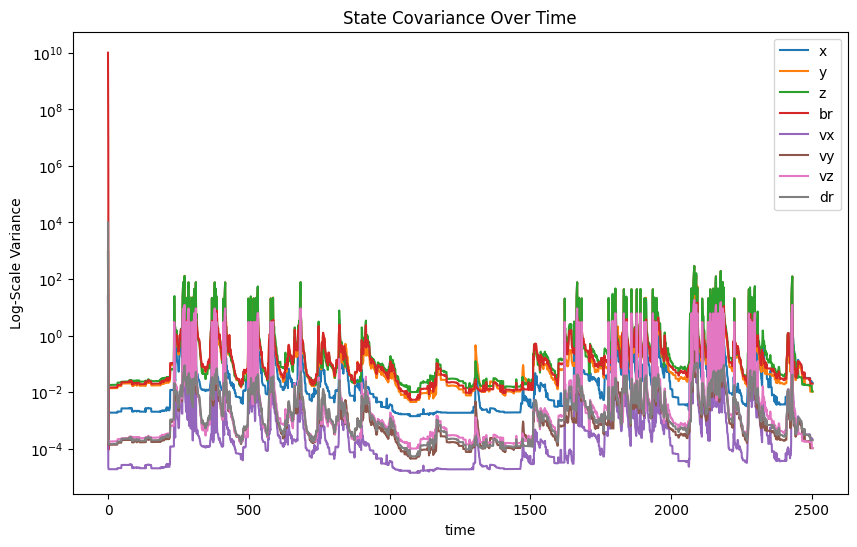

In [12]:
# Create the plot
plt.figure(figsize=(10, 6))

# Plot each of the 8 elements across all epochs
labels = ['x', 'y', 'z', 'br', 'vx', 'vy', 'vz', 'dr']
for i in range(8):
    plt.semilogy(time_grid, cov_diag[i, :], label=labels[i])

# Labels and title
plt.xlabel('time')
plt.ylabel('Log-Scale Variance')
plt.title('State Covariance Over Time')

# Legend
plt.legend()

# Save as PDF (optional)
#plt.savefig("state_cov.pdf", format="pdf")

# Show the plot
plt.show()

In [13]:
kf_lat, kf_long, kf_alt = ecef_to_geodetic_epochs(state_estimates[0:3,:], max_iterations=10, tolerance=1e-9)

Epoch 0: Converged in 8 iterations.
Epoch 1: Converged in 6 iterations.
Epoch 2: Converged in 5 iterations.
Epoch 3: Converged in 6 iterations.
Epoch 4: Converged in 6 iterations.
Epoch 5: Converged in 5 iterations.
Epoch 6: Converged in 5 iterations.
Epoch 7: Converged in 5 iterations.
Epoch 8: Converged in 5 iterations.
Epoch 9: Converged in 5 iterations.
Epoch 10: Converged in 5 iterations.
Epoch 11: Converged in 5 iterations.
Epoch 12: Converged in 5 iterations.
Epoch 13: Converged in 5 iterations.
Epoch 14: Converged in 5 iterations.
Epoch 15: Converged in 5 iterations.
Epoch 16: Converged in 5 iterations.
Epoch 17: Converged in 5 iterations.
Epoch 18: Converged in 5 iterations.
Epoch 19: Converged in 5 iterations.
Epoch 20: Converged in 5 iterations.
Epoch 21: Converged in 5 iterations.
Epoch 22: Converged in 5 iterations.
Epoch 23: Converged in 5 iterations.
Epoch 24: Converged in 5 iterations.
Epoch 25: Converged in 5 iterations.
Epoch 26: Converged in 5 iterations.
Epoch 27: C

In [14]:
kf_ve, kf_vn, kf_vu = ecef_to_neu_velocity(state_estimates[4:7,:], kf_long, kf_lat)

## Error Calculation

In [15]:
# Defining some constants
a = 6378137 # Semi-major axis (meters)
ecc = 0.08181919 # Eccentricity

In [16]:
nls_results = (nls_lat, nls_long, nls_alt, nls_ve, nls_vn, nls_vu)
kf_results = (kf_lat, kf_long, kf_alt, kf_ve, kf_vn, kf_vu)
ref_data = (np.radians(reference_data['ref_lat']), np.radians(reference_data['ref_long']), reference_data['ref_alt'], reference_data['ref_ve'], reference_data['ref_vn'], reference_data['ref_vu'])

### NLS

In [17]:
# Compute position errors
nls_position_errors = calculate_position_errors(ref_data, nls_results, a, ecc)

# Calculate STD position error
nls_std_error = calculate_std_position_error(nls_position_errors)
print("Error STD: ", {k: round(v, 3) for k, v in nls_std_error.items()})

# Calculate RMS position error
nls_rms_error = calculate_rms_position_error(nls_position_errors)
print("Error RMS: ", {k: round(v, 3) for k, v in nls_rms_error.items()})

# Calculate maximum position error
nls_max_error = calculate_max_position_error(nls_position_errors)
print("Error Max: ", {k: round(v, 3) for k, v in nls_max_error.items()})

Error STD:  {'east': 12.92, 'north': 8.511, '2d': 14.256, 'altitude': 51.32, '3d': 51.762}
Error RMS:  {'east': 13.914, 'north': 14.074, '2d': 19.791, 'altitude': 51.374, '3d': 55.054}
Error Max:  {'east': 589.423, 'north': 305.467, '2d': 663.874, 'altitude': 2428.046, '3d': 2517.168}


In [18]:
# Compute Velocity errors

nls_velocity_errors = calculate_velocity_errors(ref_data, nls_results)

# Calculate STD velocity error
nls_vel_std_error = calculate_std_velocity_error(nls_velocity_errors)
print("Error STD: ", {k: round(v, 3) for k, v in nls_vel_std_error.items()})

# Calculate RMS velocity error
nls_vel_rms_error = calculate_rms_velocity_error(nls_velocity_errors)
print("Error RMS: ", {k: round(v, 3) for k, v in nls_vel_rms_error.items()})

# Calculate maximum velocity error
nls_vel_max_error = calculate_max_velocity_error(nls_velocity_errors)
print("Error Max: ", {k: round(v, 3) for k, v in nls_vel_max_error.items()})

Error STD:  {'east': 2.495, 'north': 1.34, 'up': 10.176}
Error RMS:  {'east': 2.496, 'north': 1.34, 'up': 10.178}
Error Max:  {'east': 124.464, 'north': 65.579, 'up': 508.449}


### KF

In [19]:
# Compute position errors
kf_position_errors = calculate_position_errors(ref_data, kf_results, a, ecc)

# Calculate STD position error
kf_std_error = calculate_std_position_error(kf_position_errors)
print("Error STD: ", {k: round(v, 3) for k, v in kf_std_error.items()})

# Calculate RMS position error
kf_rms_error = calculate_rms_position_error(kf_position_errors)
print("Error RMS: ", {k: round(v, 3) for k, v in kf_rms_error.items()})

# Calculate maximum position error
kf_max_error = calculate_max_position_error(kf_position_errors)
print("Error Max: ", {k: round(v, 3) for k, v in kf_max_error.items()})

Error STD:  {'east': 3.263, 'north': 5.112, '2d': 4.951, 'altitude': 11.594, '3d': 5.87}
Error RMS:  {'east': 6.085, 'north': 11.517, '2d': 13.025, 'altitude': 11.654, '3d': 17.478}
Error Max:  {'east': 31.292, 'north': 61.797, '2d': 62.518, 'altitude': 66.434, '3d': 69.586}


In [20]:
# Calculate Velocity Errors

kf_velocity_errors = calculate_velocity_errors(ref_data, kf_results)

# Calculate STD velocity error
kf_vel_std_error = calculate_std_velocity_error(kf_velocity_errors)
print("Error STD: ", {k: round(v, 3) for k, v in kf_vel_std_error.items()})

# Calculate RMS velocity error
kf_vel_rms_error = calculate_rms_velocity_error(kf_velocity_errors)
print("Error RMS: ", {k: round(v, 3) for k, v in kf_vel_rms_error.items()})

# Calculate maximum velocity error
kf_vel_max_error = calculate_max_velocity_error(kf_velocity_errors)
print("Error Max: ", {k: round(v, 3) for k, v in kf_vel_max_error.items()})

Error STD:  {'east': 0.224, 'north': 0.296, 'up': 0.389}
Error RMS:  {'east': 0.225, 'north': 0.296, 'up': 0.389}
Error Max:  {'east': 3.033, 'north': 7.622, 'up': 3.644}


## Plotting Results

### Dilution of Precision (DOP) & Jacobian Condition Number

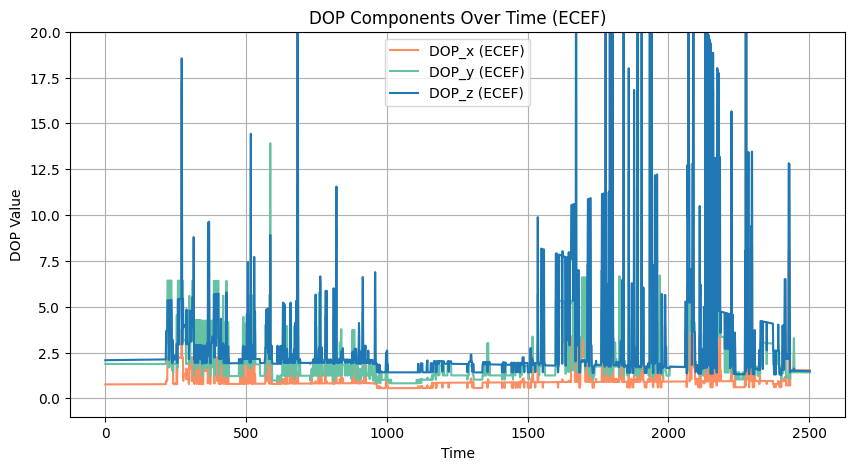

In [21]:
# Create the plot
plt.figure(figsize=(10, 5))

# Plot DOP_x, DOP_y, and DOP_z over time
plt.plot(time_grid, DOP_nls[0, :], label="DOP_x (ECEF)", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, DOP_nls[1, :], label="DOP_y (ECEF)", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, DOP_nls[2, :], label="DOP_z (ECEF)", linestyle='-', color='#1f77b4')  # Blue
#plt.plot(time_grid, DOP_kf[3, :], label="PDOP", linestyle='-', color='#9467bd')  # Purple


# Labels and title
plt.xlabel("Time")
plt.ylabel("DOP Value")
plt.title("DOP Components Over Time (ECEF)")

# Legend
plt.legend()

plt.ylim(-1,20)

# Grid for better visualization
plt.grid(True)

# Save as PDF (optional)
#plt.savefig("DOP.pdf", format="pdf")

# Show the plot
plt.show()


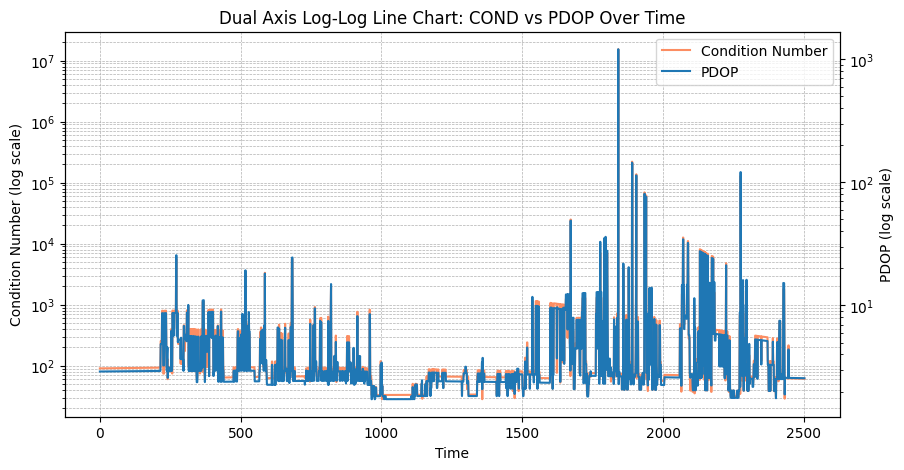

In [22]:
# Create the figure and axis
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot COND on primary y-axis (log scale)
line1, = ax1.plot(time_grid, COND.squeeze(), '#fc8d62', label='Condition Number')
ax1.set_xlabel('Time')
ax1.set_ylabel('Condition Number (log scale)', color='black')
ax1.set_yscale('log')  # Logarithmic scale for COND
ax1.tick_params(axis='y', labelcolor='black')

# Create a secondary y-axis (log scale)
ax2 = ax1.twinx()
line2, = ax2.plot(time_grid, DOP_nls[3,:], '#1f77b4', label='PDOP')
ax2.set_ylabel('PDOP (log scale)', color='black')
ax2.set_yscale('log')  # Logarithmic scale for PDOP
ax2.tick_params(axis='y', labelcolor='black')

# Title and grid
plt.title('Dual Axis Log-Log Line Chart: COND vs PDOP Over Time')
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Combine legends
lines = [line1, line2]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc='upper right')

# Save as PDF (optional)
#plt.savefig("COND_DOP.pdf", format="pdf")

# Show plot
plt.show()


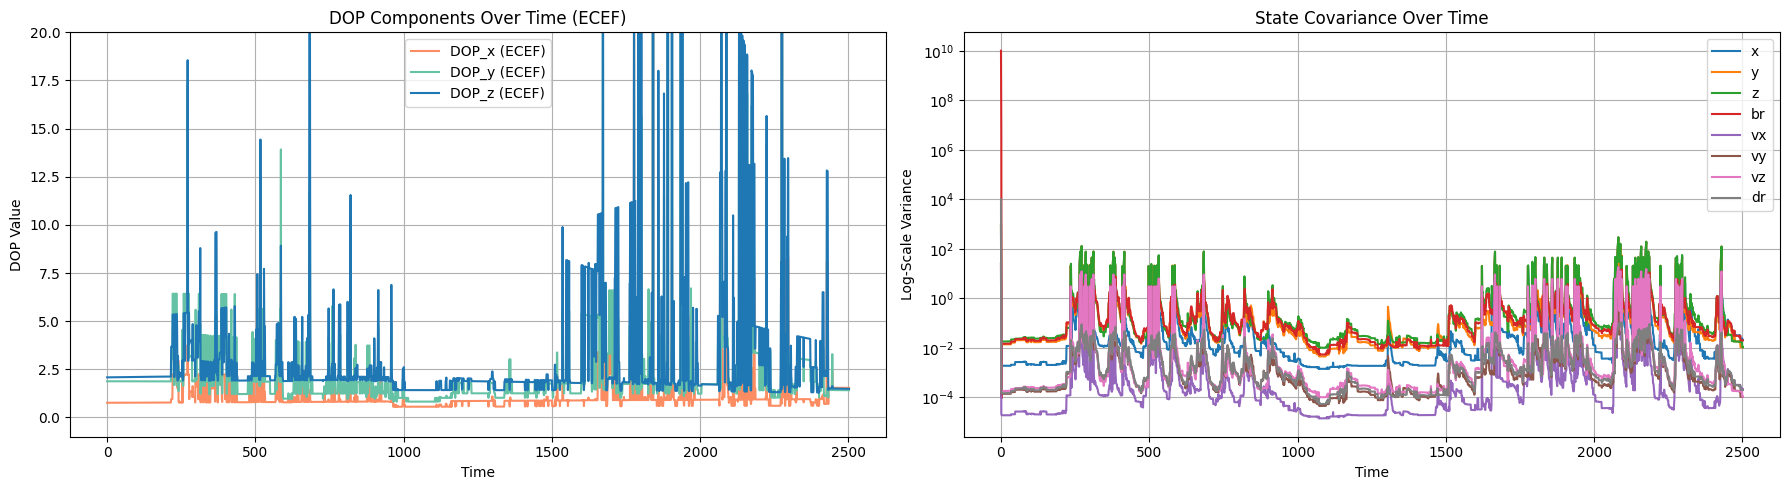

In [23]:
# Create a 1x2 subplot figure
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# First subplot: DOP Components Over Time (ECEF)
axes[0].plot(time_grid, DOP_nls[0, :], label="DOP_x (ECEF)", linestyle='-', color='#fc8d62')  # Orange
axes[0].plot(time_grid, DOP_nls[1, :], label="DOP_y (ECEF)", linestyle='-', color='#66c2a5')  # Teal
axes[0].plot(time_grid, DOP_nls[2, :], label="DOP_z (ECEF)", linestyle='-', color='#1f77b4')  # Blue

axes[0].set_xlabel("Time")
axes[0].set_ylabel("DOP Value")
axes[0].set_title("DOP Components Over Time (ECEF)")
axes[0].legend()
axes[0].set_ylim(-1, 20)
axes[0].grid(True)

# Second subplot: State Covariance Over Time
labels = ['x', 'y', 'z', 'br', 'vx', 'vy', 'vz', 'dr']
for i in range(8):
    axes[1].semilogy(time_grid, cov_diag[i, :], label=labels[i])  # Log-scale plot

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Log-Scale Variance")
axes[1].set_title("State Covariance Over Time")
axes[1].legend()
axes[1].grid(True)

# Adjust layout for better spacing
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("DOP_state_cov.pdf", format="pdf")

# Show the figure
plt.show()


### Position

#### Latitude

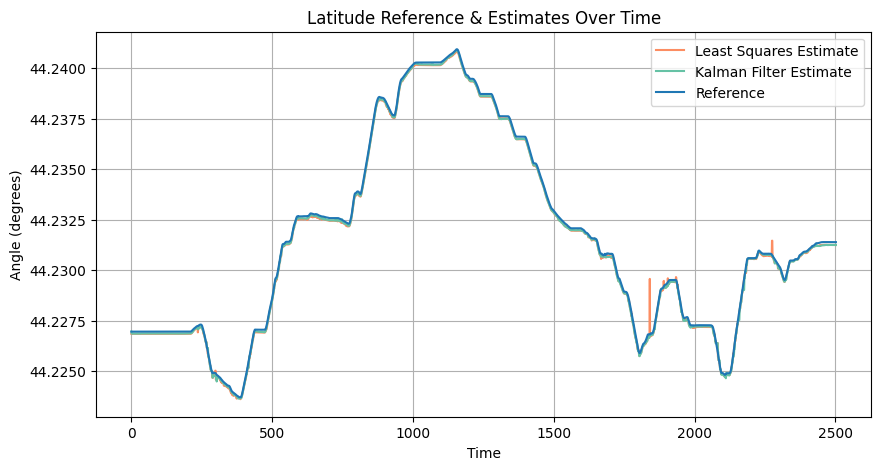

In [24]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, np.degrees(nls_lat), label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, np.degrees(kf_lat), label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_lat'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Latitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

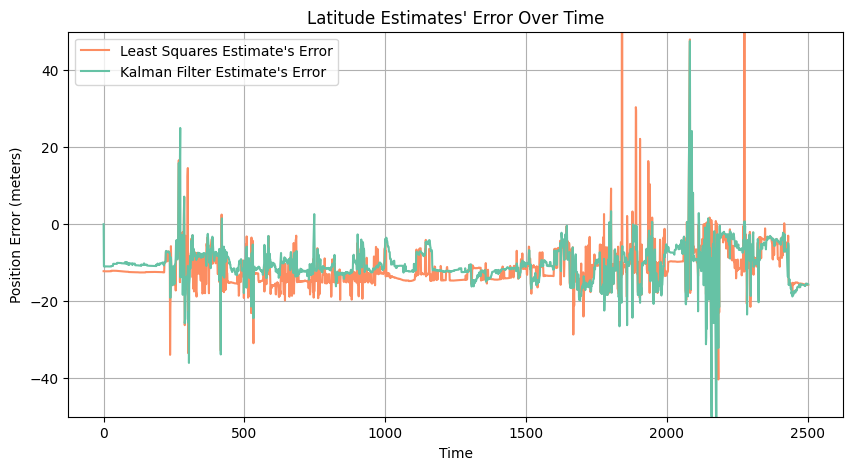

In [25]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_position_errors['north'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_position_errors['north'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("Latitude Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-50,50)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Longitude

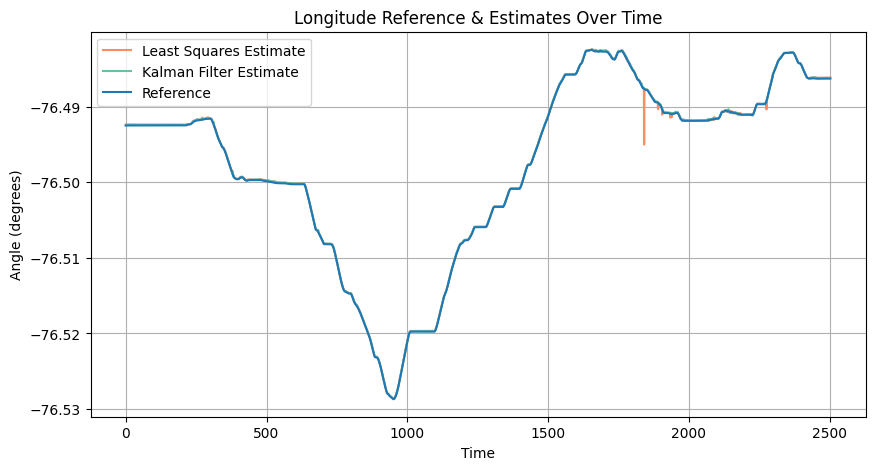

In [26]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, np.degrees(nls_long), label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, np.degrees(kf_long), label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_long'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Longitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

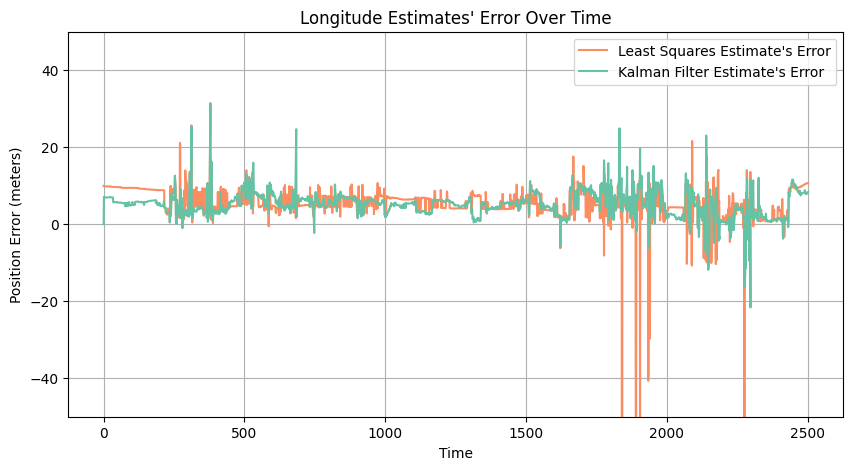

In [27]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_position_errors['east'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_position_errors['east'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("Longitude Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-50,50)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Lat-Long 

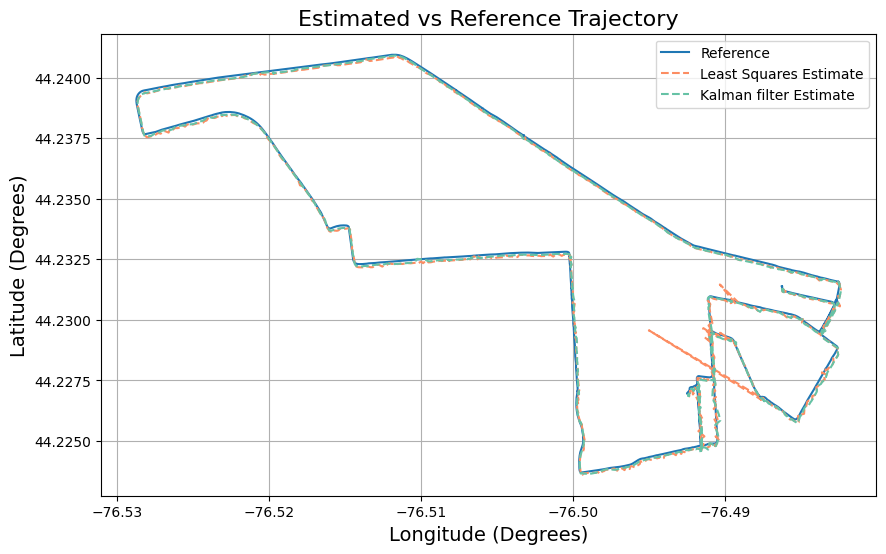

In [28]:
plt.figure(figsize=(10, 6))

# Plot reference trajectory
plt.plot(reference_data['ref_long'], reference_data['ref_lat'], '-', color='#1f77b4', label="Reference")  # Blue

# Plot high-end estimate trajectory
plt.plot(np.degrees(nls_long), np.degrees(nls_lat), '--', color='#fc8d62', label="Least Squares Estimate")  # Orange

# Plot low-end estimate trajectory
plt.plot(np.degrees(kf_long), np.degrees(kf_lat), '--', color='#66c2a5', label="Kalman filter Estimate")  # Teal

# Labels and title
plt.xlabel("Longitude (Degrees)", fontsize=14, color='black')
plt.ylabel("Latitude (Degrees)", fontsize=14, color='black')
plt.title("Estimated vs Reference Trajectory", fontsize=16)

# Add a legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Save as PDF (optional)
#plt.savefig("trajectory.pdf", format="pdf")

# Show the plot
plt.show()

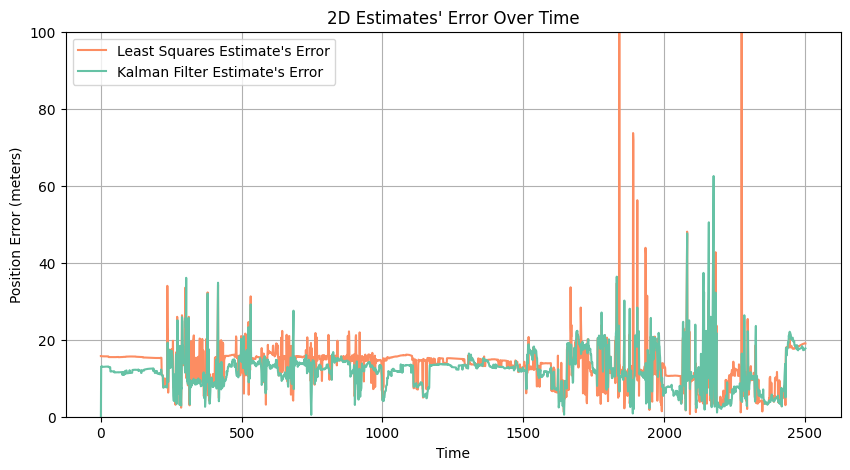

In [29]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_position_errors['2d'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_position_errors['2d'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("2D Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(0,100)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

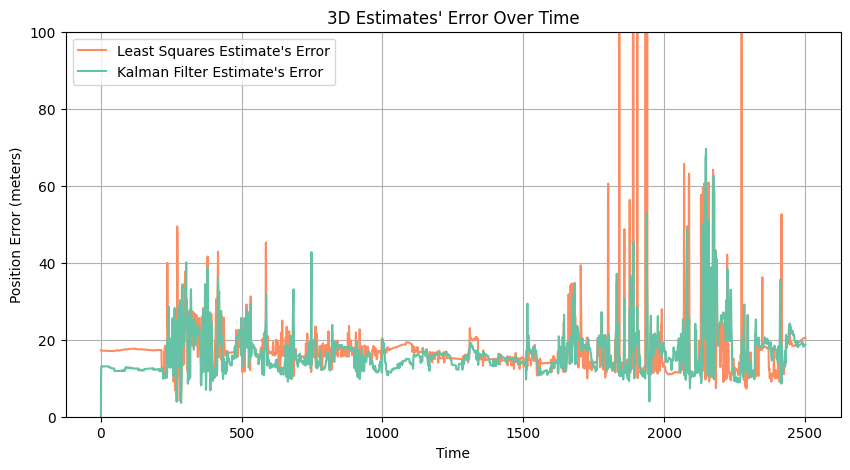

In [30]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_position_errors['3d'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_position_errors['3d'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("3D Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(0,100)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

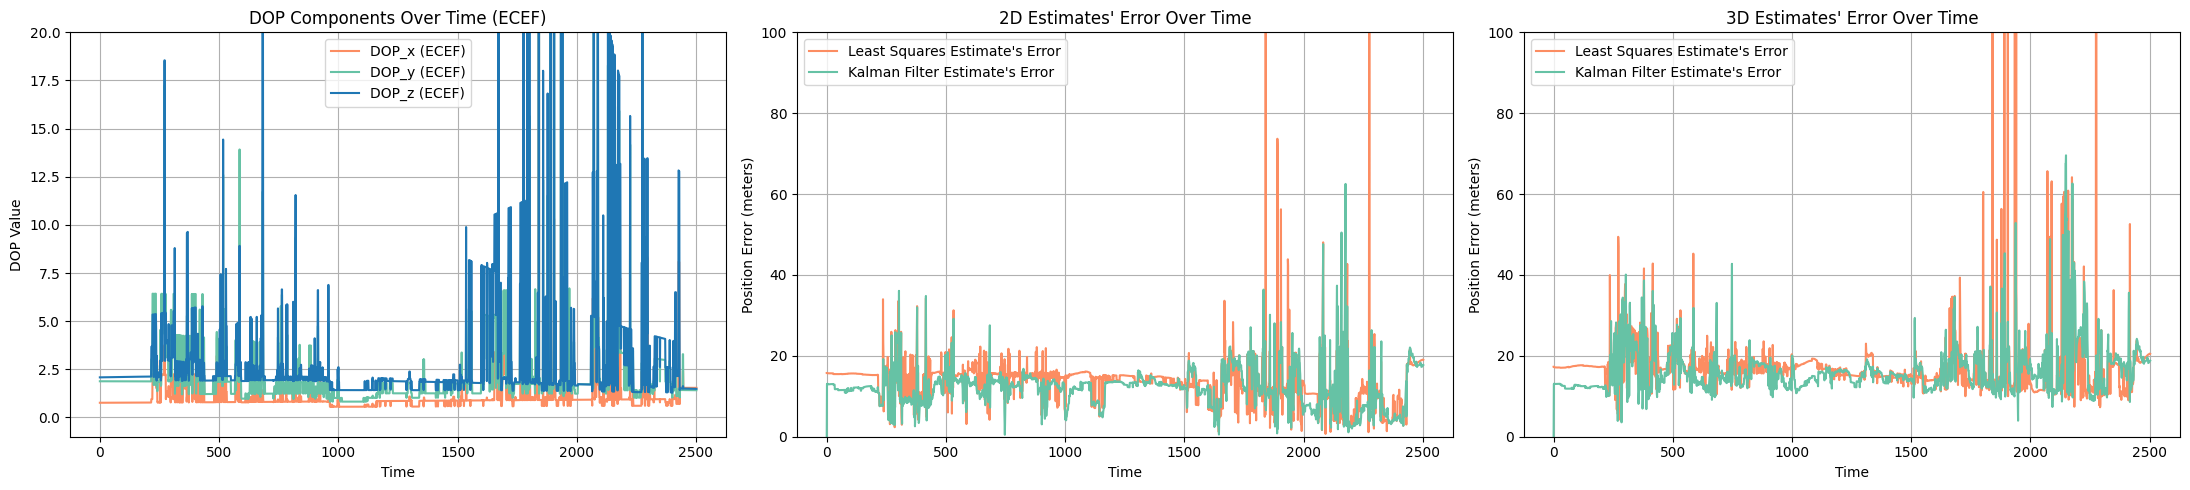

In [31]:
# Create a 1x3 subplot figure
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

# First plot: DOP Components Over Time (ECEF)
axes[0].plot(time_grid, DOP_nls[0, :], label="DOP_x (ECEF)", linestyle='-', color='#fc8d62')  # Orange
axes[0].plot(time_grid, DOP_nls[1, :], label="DOP_y (ECEF)", linestyle='-', color='#66c2a5')  # Teal
axes[0].plot(time_grid, DOP_nls[2, :], label="DOP_z (ECEF)", linestyle='-', color='#1f77b4')  # Blue

axes[0].set_xlabel("Time")
axes[0].set_ylabel("DOP Value")
axes[0].set_title("DOP Components Over Time (ECEF)")
axes[0].legend()
axes[0].set_ylim(-1, 20)
axes[0].grid(True)

# Second plot: 2D Estimates' Error Over Time
axes[1].plot(time_grid, nls_position_errors['2d'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1].plot(time_grid, kf_position_errors['2d'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

axes[1].set_xlabel("Time")
axes[1].set_ylabel("Position Error (meters)")
axes[1].set_title("2D Estimates' Error Over Time")
axes[1].legend()
axes[1].set_ylim(0, 100)
axes[1].grid(True)

# Third plot: 3D Estimates' Error Over Time
axes[2].plot(time_grid, nls_position_errors['3d'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[2].plot(time_grid, kf_position_errors['3d'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

axes[2].set_xlabel("Time")
axes[2].set_ylabel("Position Error (meters)")
axes[2].set_title("3D Estimates' Error Over Time")
axes[2].legend()
axes[2].set_ylim(0, 100)
axes[2].grid(True)

# Adjust layout to prevent overlapping
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("DOP2D3D.pdf", format="pdf")

# Show the figure
plt.show()


#### Altitude

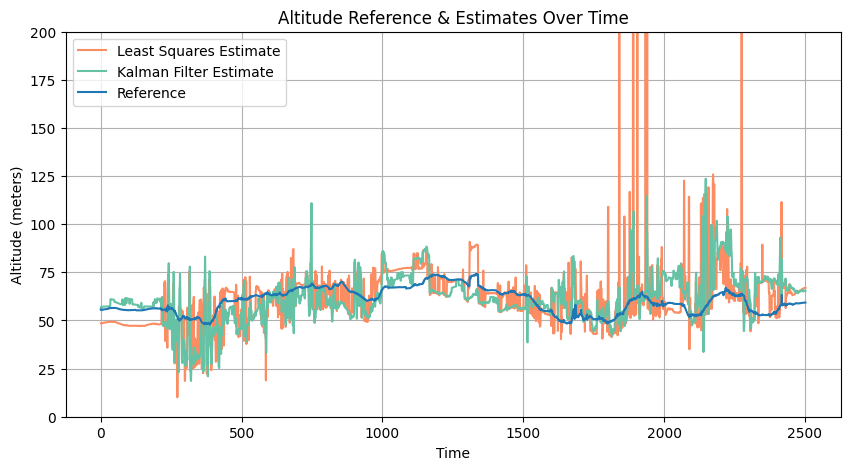

In [32]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_alt, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_alt, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_alt'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Altitude (meters)")
plt.title("Altitude Reference & Estimates Over Time")

# Legend
plt.legend()

plt.ylim(0,200)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

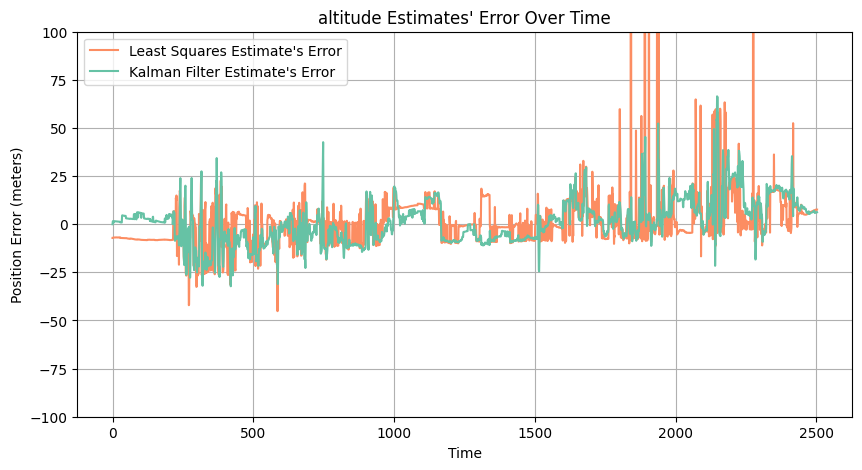

In [33]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_position_errors['altitude'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_position_errors['altitude'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("altitude Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-100,100)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

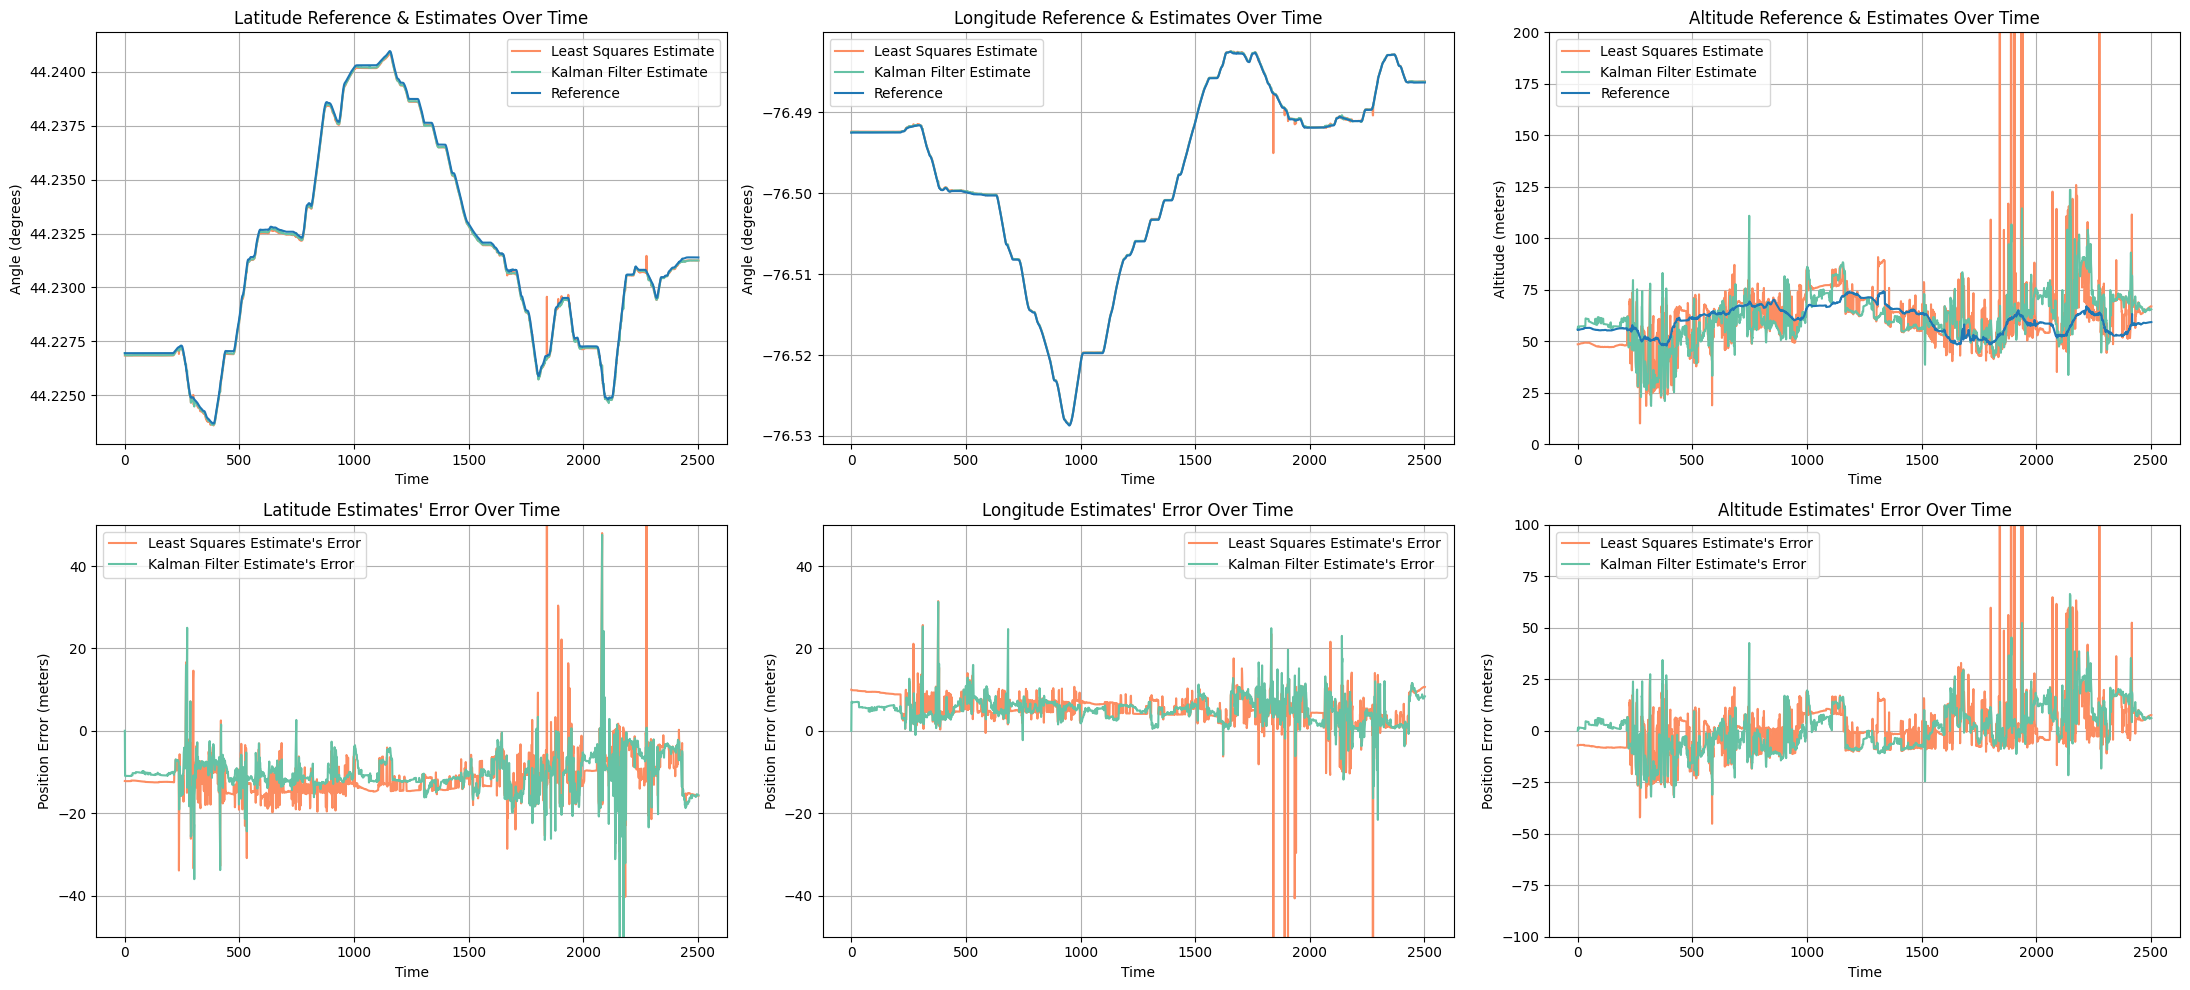

In [34]:
# Create a 2x3 subplot figure
fig, axes = plt.subplots(2, 3, figsize=(22, 10))

# First row: Latitude, Longitude, and Altitude Estimates Over Time
axes[0, 0].plot(time_grid, np.degrees(nls_lat), label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 0].plot(time_grid, np.degrees(kf_lat), label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 0].plot(time_grid, reference_data['ref_lat'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel("Angle (degrees)")
axes[0, 0].set_title("Latitude Reference & Estimates Over Time")
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(time_grid, np.degrees(nls_long), label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 1].plot(time_grid, np.degrees(kf_long), label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 1].plot(time_grid, reference_data['ref_long'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel("Angle (degrees)")
axes[0, 1].set_title("Longitude Reference & Estimates Over Time")
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[0, 2].plot(time_grid, nls_alt, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 2].plot(time_grid, kf_alt, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 2].plot(time_grid, reference_data['ref_alt'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 2].set_xlabel("Time")
axes[0, 2].set_ylabel("Altitude (meters)")
axes[0, 2].set_title("Altitude Reference & Estimates Over Time")
axes[0, 2].set_ylim(0, 200)
axes[0, 2].legend()
axes[0, 2].grid(True)

# Second row: Latitude, Longitude, and Altitude Estimates' Error Over Time
axes[1, 0].plot(time_grid, nls_position_errors['north'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 0].plot(time_grid, kf_position_errors['north'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 0].set_xlabel("Time")
axes[1, 0].set_ylabel("Position Error (meters)")
axes[1, 0].set_title("Latitude Estimates' Error Over Time")
axes[1, 0].set_ylim(-50, 50)
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(time_grid, nls_position_errors['east'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 1].plot(time_grid, kf_position_errors['east'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 1].set_xlabel("Time")
axes[1, 1].set_ylabel("Position Error (meters)")
axes[1, 1].set_title("Longitude Estimates' Error Over Time")
axes[1, 1].set_ylim(-50, 50)
axes[1, 1].legend()
axes[1, 1].grid(True)

axes[1, 2].plot(time_grid, nls_position_errors['altitude'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 2].plot(time_grid, kf_position_errors['altitude'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 2].set_xlabel("Time")
axes[1, 2].set_ylabel("Position Error (meters)")
axes[1, 2].set_title("Altitude Estimates' Error Over Time")
axes[1, 2].set_ylim(-100, 100)
axes[1, 2].legend()
axes[1, 2].grid(True)

# Adjust layout to prevent overlapping
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("pos_err.pdf", format="pdf")

# Show the figure
plt.show()


### Velocity

#### East Velocity

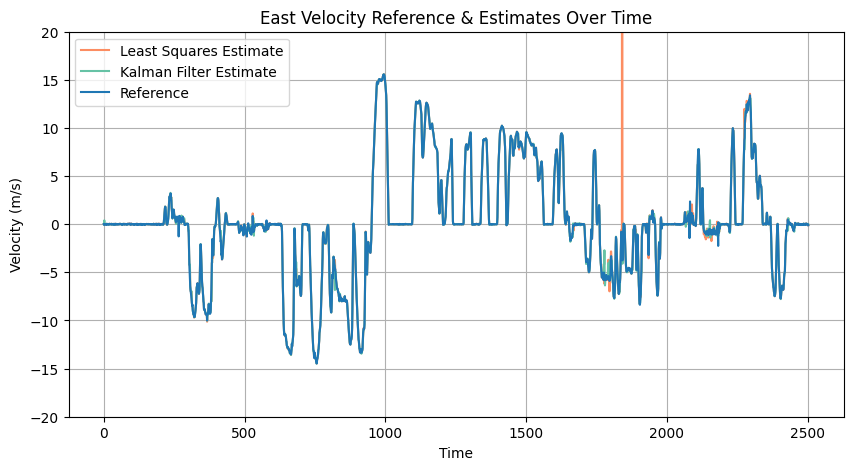

In [35]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_ve, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_ve, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_ve'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("East Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

plt.ylim(-20,20)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

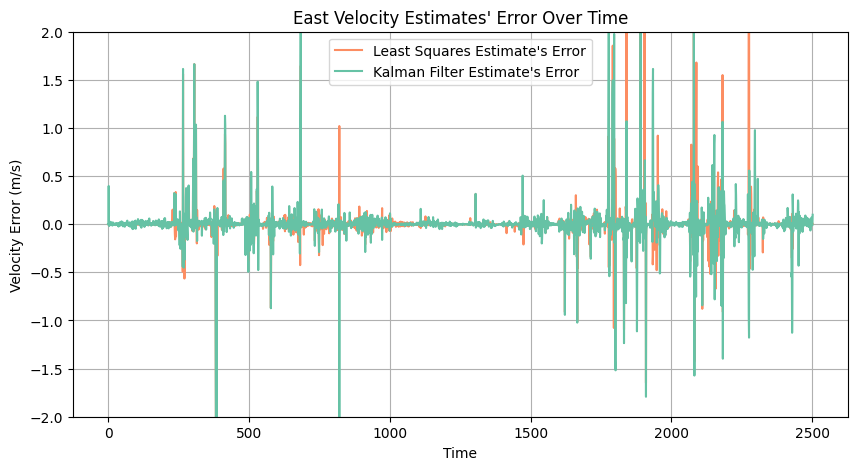

In [36]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_velocity_errors['east'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_velocity_errors['east'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("East Velocity Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-2,2)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### North Velocity

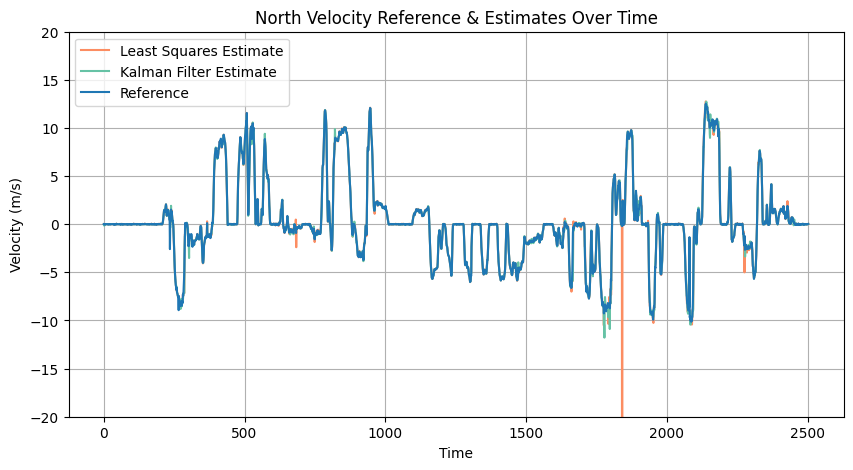

In [37]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_vn, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_vn, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_vn'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("North Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

plt.ylim(-20,20)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

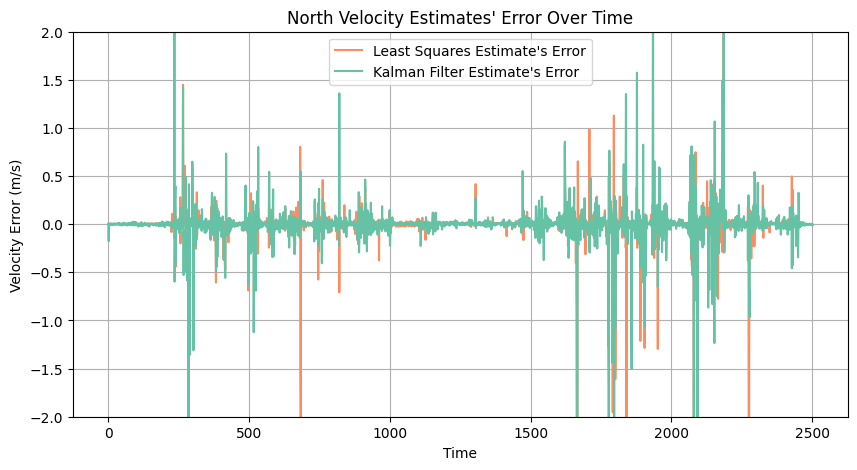

In [38]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_velocity_errors['north'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_velocity_errors['north'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("North Velocity Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-2,2)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Up Velocity

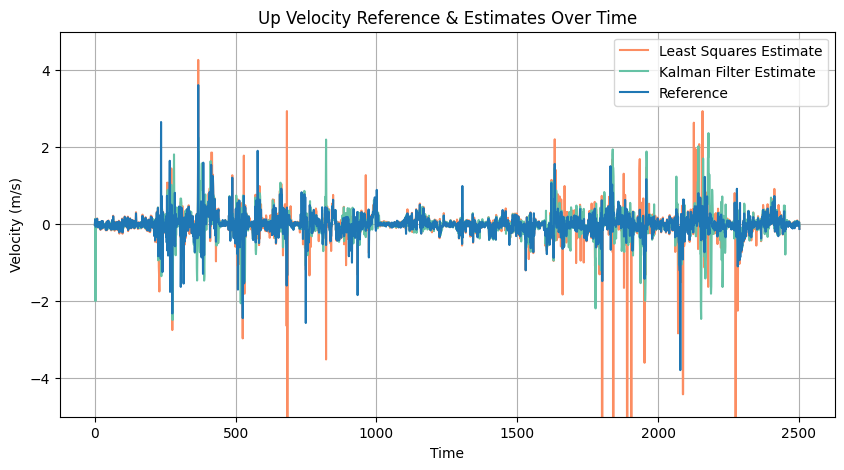

In [39]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_vu, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_vu, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
plt.plot(time_grid, reference_data['ref_vu'], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("Up Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

plt.ylim(-5, 5)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

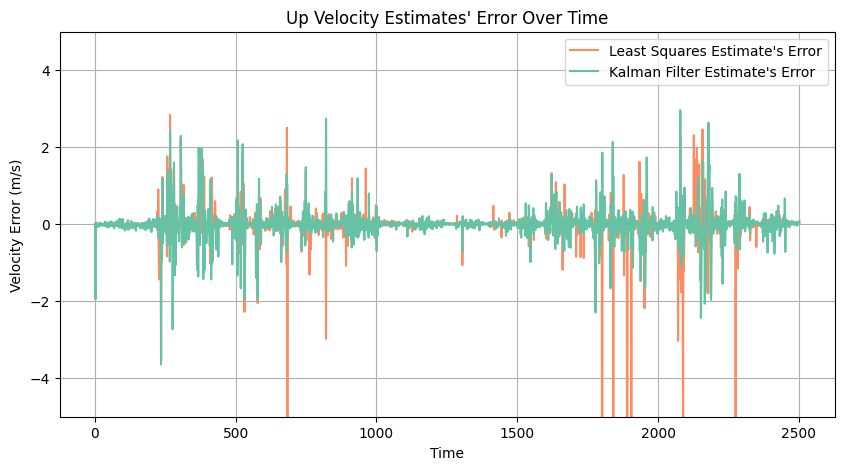

In [40]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, nls_velocity_errors['up'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, kf_velocity_errors['up'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("Up Velocity Estimates' Error Over Time")

# Legend
plt.legend()

plt.ylim(-5,5)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

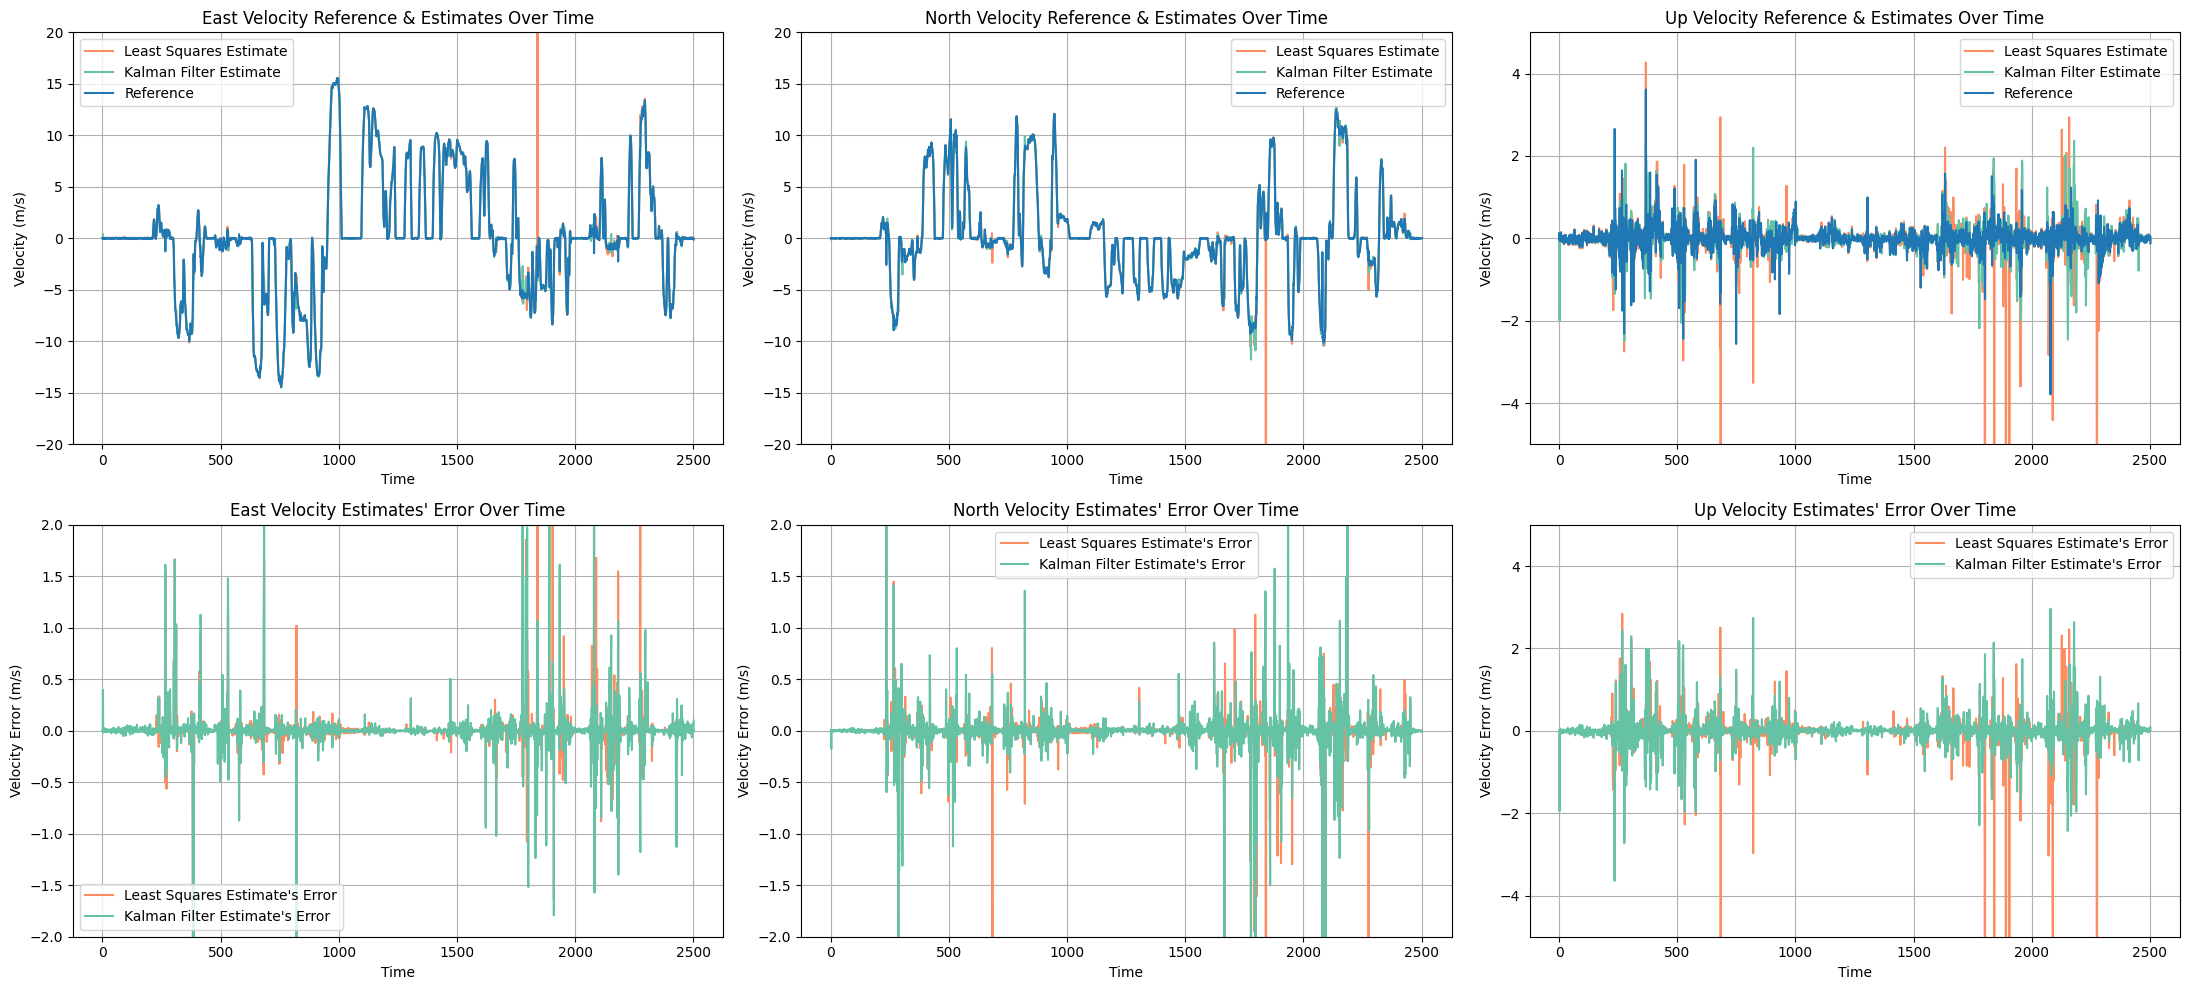

In [41]:
# Create a 2x3 subplot figure
fig, axes = plt.subplots(2, 3, figsize=(22, 10))

# First row: East, North, and Up Velocity Estimates Over Time
axes[0, 0].plot(time_grid, nls_ve, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 0].plot(time_grid, kf_ve, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 0].plot(time_grid, reference_data['ref_ve'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel("Velocity (m/s)")
axes[0, 0].set_title("East Velocity Reference & Estimates Over Time")
axes[0, 0].set_ylim(-20, 20)
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(time_grid, nls_vn, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 1].plot(time_grid, kf_vn, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 1].plot(time_grid, reference_data['ref_vn'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel("Velocity (m/s)")
axes[0, 1].set_title("North Velocity Reference & Estimates Over Time")
axes[0, 1].set_ylim(-20, 20)
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[0, 2].plot(time_grid, nls_vu, label="Least Squares Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 2].plot(time_grid, kf_vu, label="Kalman Filter Estimate", linestyle='-', color='#66c2a5')  # Teal
axes[0, 2].plot(time_grid, reference_data['ref_vu'], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 2].set_xlabel("Time")
axes[0, 2].set_ylabel("Velocity (m/s)")
axes[0, 2].set_title("Up Velocity Reference & Estimates Over Time")
axes[0, 2].set_ylim(-5, 5)
axes[0, 2].legend()
axes[0, 2].grid(True)

# Second row: East, North, and Up Velocity Estimates' Error Over Time
axes[1, 0].plot(time_grid, nls_velocity_errors['east'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 0].plot(time_grid, kf_velocity_errors['east'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 0].set_xlabel("Time")
axes[1, 0].set_ylabel("Velocity Error (m/s)")
axes[1, 0].set_title("East Velocity Estimates' Error Over Time")
axes[1, 0].set_ylim(-2, 2)
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(time_grid, nls_velocity_errors['north'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 1].plot(time_grid, kf_velocity_errors['north'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 1].set_xlabel("Time")
axes[1, 1].set_ylabel("Velocity Error (m/s)")
axes[1, 1].set_title("North Velocity Estimates' Error Over Time")
axes[1, 1].set_ylim(-2, 2)
axes[1, 1].legend()
axes[1, 1].grid(True)

axes[1, 2].plot(time_grid, nls_velocity_errors['up'], label="Least Squares Estimate's Error", linestyle='-', color='#fc8d62')  # Orange
axes[1, 2].plot(time_grid, kf_velocity_errors['up'], label="Kalman Filter Estimate's Error", linestyle='-', color='#66c2a5')  # Teal
axes[1, 2].set_xlabel("Time")
axes[1, 2].set_ylabel("Velocity Error (m/s)")
axes[1, 2].set_title("Up Velocity Estimates' Error Over Time")
axes[1, 2].set_ylim(-5, 5)
axes[1, 2].legend()
axes[1, 2].grid(True)

# Adjust layout to prevent overlapping
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("vel_err.pdf", format="pdf")

# Show the figure
plt.show()
